# Design, evaluate and compare parametric covers

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/parametric_cover_design.ipynb) · [GitHub preview](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/parametric_cover_design.ipynb)

A **parametric cover** pays an amount fixed in advance when a measured index reaches stated thresholds, whatever the loss turns out to be. The gap between payout and loss is the **basis risk**. This notebook uses `crc_sdk.parametric` to create covers on one hazard index for one illustrative asset, design some of them for different goals at the same premium budget, evaluate every cover on simulated years that its design never saw, and compare the covers on overall coverage, tail coverage and basis risk.

```text
HazardDataset.crc_open(...).ensure_materialized()             # a fitted hazard curve per H3 cell
  .for_assets(assets).select(...).impact(...)                  # the asset and its damage curve
ParametricPlan.for_evaluation(request, value_column=...)       # the parametric plan on those curves
  .monte_carlo(...).basis_risk(...).covers(...)
  .objective(...).split(FreshDraws(...)).metrics(...)
  .write_parquet(...)                                          # one comparison table, with its setup
```

1. **Hazard**: CRC Open's fitted **Rx1day** curve (annual maximum one-day precipitation, mm/day), SSP5-8.5, 2050 horizon, in the H3 cell of one Toronto site.
2. **Loss**: a hypothetical damage curve, a made-up asset value and a stated basis-risk model.
3. **Covers**: linear, step and piecewise-linear payouts. Two have fixed terms; three are templates designed under three objectives at one premium budget.
4. **Evaluate and compare**: on fresh simulated years, with the setup of every number printed next to it.

The site, its value, the damage curve, the basis-risk model and the cover terms are illustrations, not a real property or contract. Every number below holds for this setup only; nothing here shows that one objective or payout family is better in general.

## Prepare the runtime

Requires Python 3.12+ and a crc-sdk build that includes `crc_sdk.parametric` with its `parametric` extra (the HiGHS solver). Until a crc-sdk release includes the module, the setup cell installs crc-sdk from its development branch. In Colab choose **Runtime → Run all**. No credentials are required; the first run downloads the CRC Open file that covers the site and prints its size. Packages install into the active kernel when needed. Interactive charts are available when running the notebook; saved PNG outputs also make the figures visible in GitHub's preview.

In [1]:
#@title Install dependencies and prepare this notebook
import importlib
import importlib.metadata
import importlib.util
import os
from pathlib import Path
import subprocess
import sys
import sysconfig

if sys.version_info < (3, 12):
    raise RuntimeError("Use a Python 3.12+ runtime (Colab: Runtime > Change runtime type).")

# crc_sdk.parametric is not in a crc-sdk release yet: install it from the development branch.
CRC_SDK = "crc-sdk[geometry,parametric] @ git+https://github.com/marc272/crc-sdk@parametric"
REQUIREMENTS = [
    CRC_SDK, "crc-framework>=0.6.0,<0.7",
    "duckdb>=1.4.5,<2", "numpy>=1.26,<3", "pandas>=2.2,<4",
    "plotly==6.9.0", "nbformat>=5.10,<6",
]
loaded_versions = {
    module: getattr(sys.modules[module], "__version__", None)
    for module in ("numpy", "pandas", "pyarrow", "plotly", "duckdb", "crc_sdk", "crc_framework")
    if module in sys.modules
}

def parametric_installed():
    # Looks for crc_sdk/parametric on disk without importing crc_sdk.
    spec = importlib.util.find_spec("crc_sdk")
    return (spec is not None and spec.origin is not None
            and (Path(spec.origin).parent / "parametric" / "__init__.py").is_file())

def dependencies_ready():
    try:
        from packaging.requirements import Requirement
        for requirement in map(Requirement, REQUIREMENTS):
            version = importlib.metadata.version(requirement.name)
            if version not in requirement.specifier:
                return False
        return parametric_installed() and all(
            importlib.util.find_spec(name) is not None
            for name in ("highspy", "h3", "shapely")
        )
    except (ImportError, importlib.metadata.PackageNotFoundError):
        return False

def pip_install(*arguments):
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *arguments,
    ])

stale_sdk = "crc_sdk" in loaded_versions and not parametric_installed()
if not dependencies_ready():
    if importlib.util.find_spec("pip") is None:
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"], stdout=subprocess.DEVNULL)
    pip_install(*REQUIREMENTS)
    if not parametric_installed():
        # A crc-sdk release with the same version number may already be installed.
        pip_install("--force-reinstall", "--no-deps", CRC_SDK)
    if not parametric_installed():
        raise RuntimeError("crc_sdk.parametric is still missing after installation.")
importlib.invalidate_caches()
for module, loaded in loaded_versions.items():
    installed = importlib.metadata.version(module.replace("_", "-"))
    if stale_sdk or (loaded is not None and loaded != installed):
        raise RuntimeError("Packages changed after import. Restart the kernel, then run all cells again.")
os.environ["PATH"] = sysconfig.get_path("scripts") + os.pathsep + os.environ.get("PATH", "")
IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
print(f"crc-sdk {importlib.metadata.version('crc-sdk')} with crc_sdk.parametric ready. Run the remaining cells in order.")

crc-sdk 0.11.1 with crc_sdk.parametric ready. Run the remaining cells in order.


In [2]:
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from IPython.display import display

from crc_sdk.impacts import ImpactCalibration, ImpactExpression
from crc_sdk.parametric import (
    MSE, Budget, Cover, ExpectedUncovered, Free, FreshDraws, ImpactNoise, IndexDefinition,
    LinearPayout, LossModel, MetricOptions, ParametricPlan, PiecewiseLinearPayout, StepPayout,
    WeightedCVaR, sample_curve, setup_text,
)
from crc_sdk.workflows import HazardDataset, distribution_from_hazard_row

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000
pio.defaults.default_height = 470
pd.options.display.max_rows = 80
pd.options.display.max_colwidth = 120

OBJECTIVE_COLOURS = {"mse": "#2a78d6", "expected_uncovered": "#eb6834", "weighted_cvar": "#1baf7a"}
OBJECTIVE_NAMES = {"mse": "MSE design", "expected_uncovered": "E[U] design",
                   "weighted_cvar": "Weighted-CVaR design"}
FIXED_COLOUR, LOSS_COLOUR = "#52514e", "#0b0b0b"

def objective_of(label):
    return next((key for key in OBJECTIVE_COLOURS if f"({key}" in label), None)

def colour(label):
    return OBJECTIVE_COLOURS.get(objective_of(label), FIXED_COLOUR)

def legend_name(label):
    return OBJECTIVE_NAMES.get(objective_of(label), "Fixed cover")

## Pin the hazard layer and the illustrative site

The release ID pins the published catalogue and its checksums. **Rx1day** declares `annual_value_distribution` semantics: each curve describes the distribution of one year's value, so a draw from it is one simulated year and no assumption about the curve's meaning is needed. The curves pool an ensemble of climate models, so a draw mixes model spread with year-to-year variability.

The site sits at the catalogue's Toronto coordinates. Its value, **CAD 5 million**, is made up for this illustration. `BOUNDS` (`(west, south, east, north)`) bounds the acquisition to the site's cell; change `ASSET` and `BOUNDS` together to use another location, and `HORIZON` for another published horizon.

For offline checks only, the environment variable `CRC_PARAMETRIC_CURVES` can name a local canonical hazard Parquet file holding the same layer. The next cell then reads that file with `HazardDataset.local(path)` instead of the public release, says so, and stops with an error if the file is missing rather than downloading anything.

In [3]:
RELEASE = "ssp585-global-2026-10-20-v1"
SOURCE = "https://data.riskthinking.ai/crc-open"
HAZARD = "rx1day"
PATHWAY = "ssp585"
HORIZON = 2050
ASSET = dict(asset_id="Toronto depot", longitude=-79.38, latitude=43.65, value_cad=5_000_000.0)
BOUNDS = (-79.40, 43.63, -79.36, 43.67)
OUTPUT = Path("data/parametric_cover_design")
LOCAL_CURVES = os.environ.get("CRC_PARAMETRIC_CURVES")

assets = pa.Table.from_pylist([ASSET])
display(assets.to_pandas())

,asset_id,longitude,latitude,value_cad
0,Toronto depot,-79.38,43.65,5000000.0


## Materialize the site's hazard curve

The SDK downloads and checksum-verifies the one CRC Open file that covers `BOUNDS`, keeps only Rx1day at the 2050 horizon inside the area, and writes a canonical hazard file into a reusable local cache. No curve is refitted. Later runs reuse the verified cache.

The parametric plan reads a local canonical file, so the materialized dataset is the starting point. The table below lists what the dataset declares: its unit, semantics, pooling, fitted support and source, with the source's licence and attribution.

> **About the saved outputs of this copy.** They were computed offline from the CRC Open fixture sample that crc-docs keeps under `fixtures/crc_open/ssp585-fixture-2026-10-08-v2` (a geographic sample of the CRC Open curves for SDK examples), read as a local canonical file through `CRC_PARAMETRIC_CURVES`. The cell below prints which source a run used, and the provenance printed with the comparison names it again. Running the notebook as published reads the public release, whose numbers can differ.

In [4]:
if LOCAL_CURVES:
    curves_path = Path(LOCAL_CURVES)
    if not curves_path.is_file():
        raise FileNotFoundError(
            f"CRC_PARAMETRIC_CURVES names {curves_path}, which is not a file; nothing was downloaded."
        )
    dataset = HazardDataset.local(curves_path)
    print(f"Curves come from a local canonical file ({curves_path.name}), not from the public CRC Open release.")
else:
    plan_source = (
        HazardDataset.crc_open(source=SOURCE, release=RELEASE)
        .cache(OUTPUT / "cache", mode="reuse")
        .hazards([HAZARD])
        .horizons([HORIZON])
        .for_area(BOUNDS)
    )
    selection = plan_source.resolve()   # the catalogue only; no curves yet
    print(f"Curves come from the public CRC Open release {RELEASE}: {len(selection.partitions)} file(s), "
          f"{selection.total_bytes / 1024**2:.2f} MiB before filtering.")
    dataset = plan_source.ensure_materialized()

metadata = dataset.metadata()
if metadata.return_period_support is not None:
    shortest, longest = metadata.return_period_support
else:
    frequent, rare = metadata.source_probability_support
    shortest, longest = 1 / (1 - frequent), 1 / (1 - rare)
source = metadata.source
display(pd.DataFrame([dict(
    hazard=HAZARD, unit=metadata.value_unit, value_semantics=metadata.value_semantics,
    probability_semantics=metadata.probability_semantics,
    pooling=metadata.ensemble.pooling if metadata.ensemble else None,
    severe_tail=metadata.return_period_tail, h3_resolution=metadata.h3_resolution,
    fitted_support=f"return periods {shortest:,.3f} to {longest:,.0f} years",
    provider=source.provider, dataset=source.dataset, version=source.version,
    licence=source.licence, attribution=source.attribution,
)]).T.rename(columns={0: "value"}))

Curves come from a local canonical file (rx1day-toronto-fixture.parquet), not from the public CRC Open release.


,value
hazard,rx1day
unit,mm/day
value_semantics,annual maximum one-day precipitation
probability_semantics,annual_value_distribution
pooling,pooled
severe_tail,upper
h3_resolution,5
fitted_support,"return periods 1.001 to 1,000 years"
provider,RiskThinking
dataset,crc-open-fixture


## Define the loss and the basis risk

- **Damage curve.** A hypothetical damage ratio for one-day rainfall: none up to 45 mm/day, rising through 1 % at 60 mm/day and 4 % at 90 mm/day to 10 % at 130 mm/day and above. It is an `ImpactExpression`, so its definition has a hash that the outputs record, and its calibration unit (mm/day) is checked against the dataset's unit.
- **Loss.** loss = damage ratio × the asset's value, in CAD.
- **The request** is crc-sdk's ordinary portfolio request: the dataset, the asset, the selection and the impact. `asset_curves()` shows the curve each asset is joined to: the asset's H3 cell (`spatial_match`) at the selected horizon and pathway. An H3 r5 cell describes a regional grid, not conditions at one property.
- **Basis risk** is stated, never assumed: `ImpactNoise(0.3, upper=1.0)`. The index is the Rx1day value in the asset's cell; each simulated year's damage is multiplied by a mean-one lognormal factor with σ = 0.3 and capped at total loss. The factor is an assumption of this illustration, not an estimate. It changes how large a year's loss is, not whether there is one, so a payout in a year without loss cannot occur under this model. Without any model the loss would be a function of the index, and a cover would have no basis risk by construction (`NoBasisRisk` warns about that).

In [5]:
DAMAGE = ImpactExpression.tabulated(
    [(45.0, 0.0), (60.0, 0.01), (90.0, 0.04), (130.0, 0.10)],
    calibration=ImpactCalibration(
        exposure_variable="rx1day", exposure_unit="mm/day",
        impact_metric="damage_ratio", impact_unit="1",
    ),
    clamp={"minimum": 0.0, "maximum": 1.0},
)
BASIS_RISK = ImpactNoise(0.3, upper=1.0)

request = (
    dataset.for_assets(assets)
    .select(hazard_names=[HAZARD], horizons=[HORIZON], pathways=[PATHWAY])
    .impact(DAMAGE, name="rx1day_damage", value_unit="1", value_semantics="hypothetical damage ratio")
)
curve_row = request.asset_curves().to_pylist()[0]   # the asset's canonical curve row
display(pd.DataFrame([dict(
    asset_id=curve_row["asset_id"], h3_cell=f"{curve_row['cell_index']:x}",
    spatial_match=curve_row["spatial_match"], hazard=curve_row["hazard_name"],
    horizon=curve_row["horizon"], pathway=curve_row["pathway"],
    curve_kind=curve_row["curve_kind"], curve_family=curve_row["curve_type"],
)]))
print(f"Damage curve definition: {DAMAGE.definition_hash}")

,asset_id,h3_cell,spatial_match,hazard,horizon,pathway,curve_kind,curve_family
0,Toronto depot,852b9bc7fffffff,h3_cell,rx1day,2050,ssp585,hurdle,gumbel_r


Damage curve definition: sha256:c7873c876b3c83ac5aa94d04b094f1a3aa128d8c8907858dbcb456f59706a5b0


The left panel shows the site's fitted Rx1day curve as values against return period; past the dotted line the curve is used beyond the range it was fitted on. The right panel shows the damage curve over the same rainfall values.

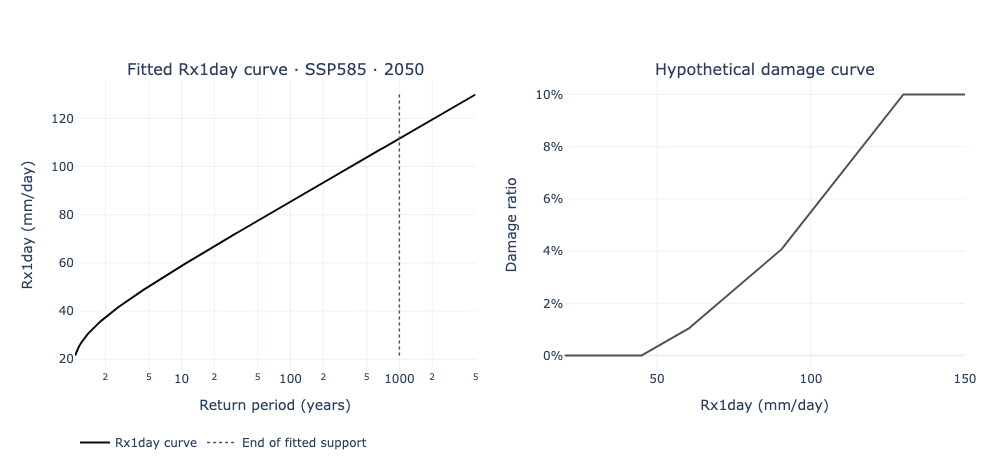

In [6]:
distribution = distribution_from_hazard_row(curve_row)
periods = np.geomspace(1.05, 5_000, 200)
rainfall = np.asarray(distribution.quantiles(1 - 1 / periods), dtype=float)
grid = np.linspace(20.0, 150.0, 261)
damage_ratio = np.asarray(DAMAGE.evaluate(grid), dtype=float)

fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.1, subplot_titles=(
    f"Fitted Rx1day curve · {PATHWAY.upper()} · {HORIZON}", "Hypothetical damage curve"))
fig.add_trace(go.Scatter(x=periods, y=rainfall, mode="lines", name="Rx1day curve",
                         line=dict(color=LOSS_COLOUR, width=2)), row=1, col=1)
fig.add_trace(go.Scatter(x=[longest, longest], y=[rainfall.min(), rainfall.max()], mode="lines",
                         name="End of fitted support", line=dict(color=FIXED_COLOUR, dash="dot", width=1.5)),
              row=1, col=1)
fig.add_trace(go.Scatter(x=grid, y=damage_ratio, mode="lines", name="Damage ratio", showlegend=False,
                         line=dict(color=FIXED_COLOUR, width=2)), row=1, col=2)
fig.update_xaxes(title_text="Return period (years)", type="log", row=1, col=1)
fig.update_yaxes(title_text=f"Rx1day ({metadata.value_unit})", row=1, col=1)
fig.update_xaxes(title_text=f"Rx1day ({metadata.value_unit})", row=1, col=2)
fig.update_yaxes(title_text="Damage ratio", tickformat=".0%", row=1, col=2)
fig.update_layout(legend=dict(orientation="h", yanchor="top", y=-0.2), margin=dict(l=75, r=35, t=80, b=100))
fig.show()

## Create the covers

Every cover pays on the same index: Rx1day at the asset, in mm/day, the year's maximum. Thresholds are in mm/day and amounts in CAD. A parameter is either a fixed number or `Free(...)`, a value a design chooses within bounds; a cover with a free parameter is a **template**.

| Cover | Payout | Terms |
| --- | --- | --- |
| `linear, fixed` | rises linearly from an attachment to an exhaustion point | attachment 60, exhaustion 100 mm/day, limit CAD 250,000 |
| `step, fixed` | pays a level per band | CAD 50,000 from 60, 125,000 from 75, 250,000 from 90 mm/day |
| `linear` | template | attachment chosen on a grid from 50 to 70 mm/day; exhaustion 100 mm/day; the limit is free |
| `step` | template | bands from 50, 60, 70, 80, 90 and 100 mm/day; the six levels are free |
| `piecewise linear` | template | knots at 45, 60, 75, 90 and 110 mm/day; the five levels are free |

The fixed terms were chosen by hand for this illustration. Each cover has a canonical JSON document and a `definition_hash`; the label is only a display name.

In [7]:
index = IndexDefinition(HAZARD, "mm/day", aggregation="annual_maximum")

def cover(payout, label):
    return Cover(index, payout, payout_unit="CAD", label=label)

FIXED = [
    cover(LinearPayout(60.0, 100.0, 250_000.0), "linear, fixed"),
    cover(StepPayout([60.0, 75.0, 90.0], [50_000.0, 125_000.0, 250_000.0]), "step, fixed"),
]
TEMPLATES = [
    cover(LinearPayout(Free(lower=50.0, upper=70.0, grid=5), 100.0, Free()), "linear"),
    cover(StepPayout([50.0, 60.0, 70.0, 80.0, 90.0, 100.0], [Free()] * 6), "step"),
    cover(PiecewiseLinearPayout([45.0, 60.0, 75.0, 90.0, 110.0], [Free()] * 5), "piecewise linear"),
]
display(pd.DataFrame([dict(
    label=item.label, family=item.payout.kind,
    free_parameters=", ".join(item.free_parameters()) or "none: fixed terms",
    definition_hash=item.definition_hash[:19] + "…",
) for item in FIXED + TEMPLATES]))

,label,family,free_parameters,definition_hash
0,"linear, fixed",linear,none: fixed terms,sha256:ebf1975fb635…
1,"step, fixed",step,none: fixed terms,sha256:a338a0c9a601…
2,linear,linear,"attachment, limit",sha256:4d722b429a81…
3,step,step,"levels[0], levels[1], levels[2], levels[3], levels[4], levels[5]",sha256:b544f8bc92cd…
4,piecewise linear,piecewise_linear,"levels[0], levels[1], levels[2], levels[3], levels[4]",sha256:df2a0a1f448a…


## Plan the designs and the out-of-sample test

- **Simulated years.** `monte_carlo(20_000, seed=42)` draws 20,000 years from the site's curve; each is one year with probability 1/20,000. The designs are chosen on these draws.
- **Objectives**, each minimised on the design draws, with U = max(loss − payout, 0) the uncovered loss of a year:
  - `MSE()`: E[(loss − payout)²]. Paying more than the loss counts as much as paying less.
  - `ExpectedUncovered()`: E[U]. Every year's shortfall counts alike; paying more than the loss earns nothing.
  - `WeightedCVaR(alpha=0.9, beta=0.9)`: 0.9 · CVaR₀.₉(U) + 0.1 · E[U]. Most of the weight is on the mean of the worst 10 % of shortfalls.
- **The same budget for every design**: `Budget(ratio=0.6)`, a premium of at most 60 % of the expected loss on the design draws, priced as the pure premium (premium = expected payout). The fixed covers are priced the same way, on the years they are evaluated on.
- **Out of sample**: `FreshDraws(20_000, seed=7)` draws 20,000 new years from the same curve with another seed. Every cover is evaluated on them; a design keeps the premium agreed at design.
- **Metrics**: tail levels β = 0.9 and 0.99, return periods 10, 50 and 100 years, and loss thresholds CAD 0 and CAD 100,000 for the false-negative rates. No threshold is hidden.

`explain()` and `setup_text` state the setup before anything is read or drawn.

In [8]:
plan = (
    ParametricPlan.for_evaluation(request, value_column="value_cad", value_unit="CAD")
    .monte_carlo(20_000, seed=42)
    .basis_risk(BASIS_RISK)
    .covers(*FIXED, *TEMPLATES)
    .objective(MSE(), ExpectedUncovered(), WeightedCVaR(alpha=0.9, beta=0.9),
               budget=Budget(ratio=0.6))
    .split(FreshDraws(20_000, seed=7))
    .metrics(MetricOptions(betas=(0.9, 0.99), return_periods=(10, 50, 100),
                           loss_thresholds=(0.0, 100_000.0)))
)
print(setup_text(plan.explain(format="json")["setup"]))

Level: asset (Toronto depot). Scenario: baseline. Basis: annual, one draw is one year.
Split: in sample, fold 0: evaluated on the design sample itself, the evaluation sample, not known yet. In-sample numbers show the fit, not out-of-sample performance.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on the evaluation sample, not known yet; designed on the design sample, not known yet; no leakage check is recorded.
Sample: Monte Carlo draws from a hazard curve, with the probability semantics the dataset declares, not known yet. Basis risk: impact noise, a mean-one lognormal factor with sigma 0.3, the noisy impact capped at 1. Loss: impact expression rx1day_damage (c7873c876b3c) for hazard values in mm/day times the asset value in column value_cad, in CAD.
Pricing: the pure premium, P = E[payout], on the evaluation sample, for the covers given as is; a design keeps its design premium, and premium_basis says which premium a row uses.
Metrics: beta 0.9, 0.99; return per

## Run the plan

`write_parquet` is the execution point: it reads the curve, draws the years, solves the nine designs (three templates under three objectives) and writes one comparison table atomically, with its setup, covers, design records, sources, licences and random-generator states in the file's metadata. Warnings about draws beyond the fitted support are recorded and printed here.

In [9]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    result = plan.write_parquet(OUTPUT / "comparison.parquet")
for warning in caught:
    print(f"{warning.category.__name__}: {warning.message}")
print(f"{result.row_count} rows: {len(FIXED) + 3 * len(TEMPLATES)} covers, in and out of sample. Written to {result.output}")

22 rows: 11 covers, in and out of sample. Written to data/parametric_cover_design/comparison.parquet


### Draws beyond the fitted support

A fitted curve can be evaluated everywhere, but it was fitted on a range of probabilities. Draws outside that range, more frequent than its shortest or rarer than its longest return period, use the curve's extrapolation. The plan counts them for each sample; the table gives the share, for the design draws and for the fresh draws.

In [10]:
setup = result.metadata.model_dump(mode="json")["setup"]
support = pd.DataFrame([dict(
    sample="design draws" if "design" in entry["roles"] else "fresh draws", draws=entry["draws"],
    more_frequent=entry["details"]["outside_support"]["below"],
    rarer=entry["details"]["outside_support"]["above"],
) for entry in setup["samples"]])
support["share_outside"] = (support.more_frequent + support.rarer) / support.draws
display(support.style.format({"share_outside": "{:.2%}"}).hide(axis="index"))

sample,draws,more_frequent,rarer,share_outside
design draws,20000,30,17,0.24%
fresh draws,20000,22,12,0.17%


## Compare the covers out of sample

The rows below are the **out-of-sample** rows, on the fresh draws. The comparison file also holds the in-sample rows, which measure the fit on the design draws and show the gap between the two.

- **Overall coverage**: `coverage_ratio` = E[min(payout, loss)] / E[loss], the share of the expected loss that payouts cover; payouts above the loss do not count.
- **Tail coverage**: `tail_coverage_b0_9` and `tail_coverage_b0_99`, the same share in the worst 10 % and 1 % of loss years; `cvar_uncovered_b0_9` is the mean uncovered loss in the worst 10 % of shortfall years.
- **Basis risk**: `rmse`, the root mean square of loss − payout; `correlation` of payout and loss; `false_negative_rate_l0` and `false_negative_rate_l100000`, the share of years with a loss above CAD 0 or CAD 100,000 and no payout; `false_positive_rate_l0`, the share of loss-free years with a payout.
- `premium_basis` says which premium a row uses: `design` for a design, `evaluation` for a fixed cover. `unique` says whether a design is the only optimum (`None`: not checked, on the linear-programme route).

The setup text printed under the table states the asset, the basis, the samples' source and basis-risk model, the pricing and budget, the split and each design; it belongs next to every number in the table.

In [11]:
table = result.table
rows = table.filter(pc.equal(table["split"], "out_of_sample")).to_pandas().set_index("cover_label")
MONEY = ["premium", "expected_loss", "expected_payout", "expected_uncovered", "cvar_uncovered_b0_9", "rmse"]
SHARES = ["coverage_ratio", "tail_coverage_b0_9", "tail_coverage_b0_99", "false_negative_rate_l0",
          "false_negative_rate_l100000", "false_positive_rate_l0"]
comparison = rows[["premium_basis", *MONEY, *SHARES, "correlation", "unique"]]
display(comparison.style.format({**{column: "{:,.0f}" for column in MONEY},
                                 **{column: "{:.1%}" for column in SHARES},
                                 "correlation": "{:.3f}"}))
print(setup_text(result.metadata))
for line in dict.fromkeys(
    f"Source: {origin['provider']} {origin['dataset']} {origin['version']}; "
    f"licence {origin['licence']}; attribution: {origin['attribution']}."
    for origin in (entry["metadata"]["source"] for entry in result.metadata.model_dump(mode="json")["sources"])
):
    print(line)

,premium_basis,premium,expected_loss,expected_payout,expected_uncovered,cvar_uncovered_b0_9,rmse,coverage_ratio,tail_coverage_b0_9,tail_coverage_b0_99,false_negative_rate_l0,false_negative_rate_l100000,false_positive_rate_l0,correlation,unique
cover_label,,,,,,,,,,,,,,,
"linear, fixed",evaluation,"6,407","14,520","6,407","8,373","54,782","20,997",42.3%,56.7%,68.1%,70.2%,0.3%,0.0%,0.880,None
"step, fixed",evaluation,"7,180","14,520","7,180","7,710","52,612","20,620",46.9%,61.1%,66.0%,70.2%,0.3%,0.0%,0.879,None
linear (mse),design,"8,433","14,520","8,572","6,362","42,209","17,271",56.2%,70.6%,68.9%,54.3%,0.0%,0.0%,0.918,True
linear (expected_uncovered),design,"8,433","14,520","8,617","6,046","43,228","18,859",58.4%,64.1%,52.1%,32.1%,0.0%,0.0%,0.938,None
linear (weighted_cvar alpha=0.9 beta=0.9),design,"8,433","14,520","8,572","6,362","42,209","17,271",56.2%,70.6%,68.9%,54.3%,0.0%,0.0%,0.918,None
step (mse),design,"8,433","14,520","8,602","6,323","44,275","17,610",56.5%,67.0%,69.7%,32.1%,0.0%,0.0%,0.914,True
step (expected_uncovered),design,"8,433","14,520","8,644","6,046","46,284","19,060",58.4%,60.4%,55.0%,32.1%,0.0%,0.0%,0.935,None
step (weighted_cvar alpha=0.9 beta=0.9),design,"8,433","14,520","8,594","6,294","44,382","17,674",56.6%,66.1%,69.0%,32.1%,0.0%,0.0%,0.916,None
piecewise linear (mse),design,"8,433","14,520","8,603","6,268","43,649","17,164",56.8%,66.1%,71.2%,0.0%,0.0%,0.0%,0.920,True


Level: asset (Toronto depot). Scenario: baseline. Basis: annual, one draw is one year.
Split: in sample, fold 0: evaluated on the design sample itself, 20000 simulated years (draws 0 to 19999). In-sample numbers show the fit, not out-of-sample performance.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on 20000 simulated years (draws 0 to 19999); designed on 20000 simulated years (draws 0 to 19999); the leakage check passed: the two share no period of one source.
Sample: Monte Carlo draws from a hazard curve with annual_value_distribution semantics, as the dataset declares. Basis risk: impact noise, a mean-one lognormal factor with sigma 0.3, the noisy impact capped at 1. Loss: impact expression rx1day_damage (c7873c876b3c) for hazard values in mm/day times the asset value in column value_cad, in CAD.
Sample notes: 30 of 20000 draws are more frequent than the shortest fitted return period: the curve is extrapolated there. 17 of 20000 draws are rarer than the longes

The designs' terms, as chosen on the design draws, with each design's premium and how much of the budget it uses:

In [12]:
design_labels = {record["design_id"]: record["cover_label"]
                 for record in result.metadata.model_dump(mode="json")["designs"]}
display(pd.DataFrame([dict(
    design=design_labels[item.design_id], route=item.route, unique=item.unique, ties=item.ties,
    premium=item.premium, budget_use=item.budget_use,
    terms=", ".join(f"{name} {value:,.0f}" for name, value in item.parameters.items()),
) for item in result.designs]).style.format(
    {"premium": "{:,.0f}", "budget_use": "{:.1%}"}).hide(axis="index"))

design,route,unique,ties,premium,budget_use,terms
linear (mse),grid,True,0,"8,433",100.0%,"attachment 55, limit 242,021"
linear (expected_uncovered),grid,None,0,"8,433",100.0%,"attachment 50, limit 175,755"
linear (weighted_cvar alpha=0.9 beta=0.9),grid,None,0,"8,433",100.0%,"attachment 55, limit 242,021"
step (mse),qp,True,0,"8,433",100.0%,"levels[0] 7,488, levels[1] 47,040, levels[2] 98,846, levels[3] 146,837, levels[4] 207,545, levels[5] 308,433"
step (expected_uncovered),lp,None,0,"8,433",100.0%,"levels[0] 17,729, levels[1] 44,789, levels[2] 83,735, levels[3] 117,188, levels[4] 156,570, levels[5] 224,514"
step (weighted_cvar alpha=0.9 beta=0.9),lp,None,0,"8,433",100.0%,"levels[0] 8,771, levels[1] 45,825, levels[2] 96,360, levels[3] 143,563, levels[4] 214,624, levels[5] 297,366"
piecewise linear (mse),qp,True,0,"8,433",100.0%,"levels[0] 0, levels[1] 13,426, levels[2] 106,472, levels[3] 169,287, levels[4] 341,594"
piecewise linear (expected_uncovered),lp,None,0,"8,433",100.0%,"levels[0] 0, levels[1] 30,293, levels[2] 74,896, levels[3] 123,616, levels[4] 192,283"
piecewise linear (weighted_cvar alpha=0.9 beta=0.9),lp,None,0,"8,433",100.0%,"levels[0] 0, levels[1] 13,828, levels[2] 106,672, levels[3] 162,992, levels[4] 345,507"


The same out-of-sample metrics as bars, one panel per measure. Bars of one colour share an objective; grey bars are the fixed covers.

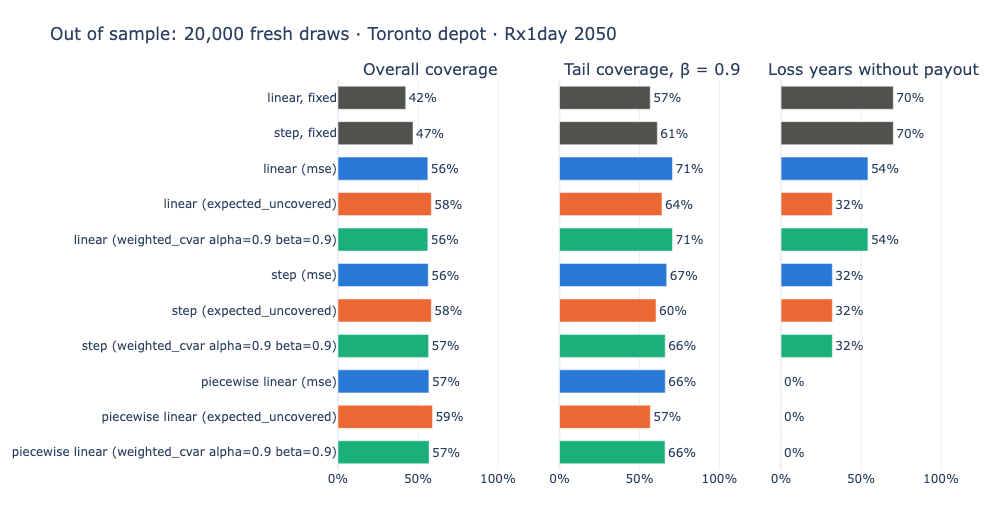

In [13]:
PANELS = [("coverage_ratio", "Overall coverage"), ("tail_coverage_b0_9", "Tail coverage, β = 0.9"),
          ("false_negative_rate_l0", "Loss years without payout")]
labels = list(comparison.index)
fig = make_subplots(rows=1, cols=3, shared_yaxes=True, horizontal_spacing=0.06,
                    subplot_titles=[title for _, title in PANELS])
for column, (metric, _) in enumerate(PANELS, start=1):
    fig.add_trace(go.Bar(
        x=comparison[metric], y=labels, orientation="h", marker_color=[colour(label) for label in labels],
        text=[f"{value:.0%}" for value in comparison[metric]], textposition="outside", cliponaxis=False,
        hovertemplate="%{y}: %{x:.1%}<extra></extra>", showlegend=False,
    ), row=1, col=column)
    fig.update_xaxes(tickformat=".0%", range=[0, 1.15], row=1, col=column)
fig.update_yaxes(autorange="reversed")
fig.update_layout(height=520, bargap=0.35, margin=dict(l=270, r=35, t=80, b=50),
                  title=f"Out of sample: 20,000 fresh draws · {ASSET['asset_id']} · Rx1day {HORIZON}")
fig.show()

## Payout functions

Each panel shows one payout family: its fixed cover (grey, dashed) and its three designs, with the loss a year would have at that Rx1day value before the basis-risk factor (black, dotted). Hover over a line for the cover's full label. Where a design's payout rises, and how far, is how it spends the shared budget across the bands.

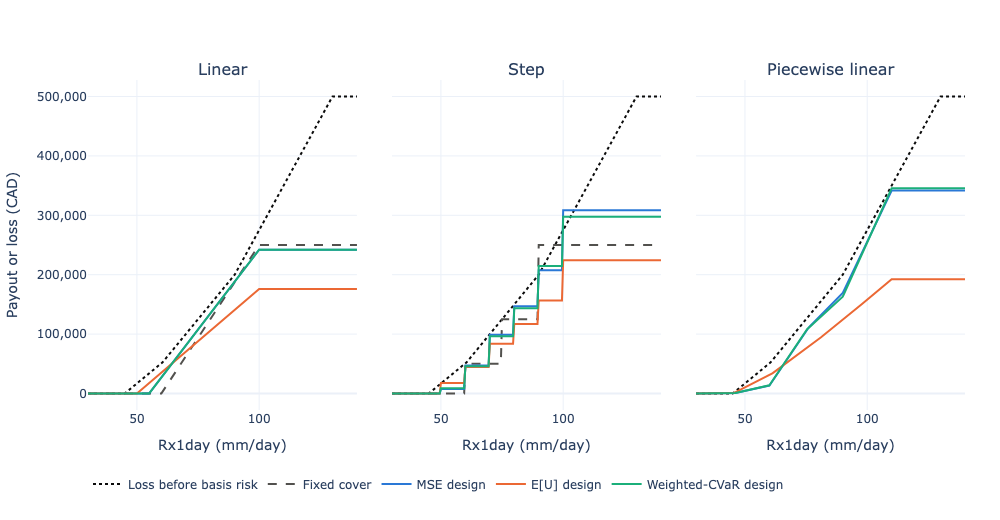

In [14]:
resolved_covers = {cover.label: cover for cover in FIXED}
resolved_covers.update({design_labels[item.design_id]: item.cover for item in result.designs})
FAMILIES = ["linear", "step", "piecewise linear"]

def family(label):
    return next(name for name in reversed(FAMILIES) if label.startswith(name))

grid = np.linspace(30.0, 140.0, 221)
shown = set()
fig = make_subplots(rows=1, cols=3, shared_yaxes=True, horizontal_spacing=0.04,
                    subplot_titles=[name.capitalize() for name in FAMILIES])
for column, name in enumerate(FAMILIES, start=1):
    fig.add_trace(go.Scatter(
        x=grid, y=ASSET["value_cad"] * np.asarray(DAMAGE.evaluate(grid), dtype=float),
        mode="lines", name="Loss before basis risk", legendgroup="loss", showlegend=column == 1,
        line=dict(color=LOSS_COLOUR, dash="dot", width=2),
    ), row=1, col=column)
    for label, resolved in resolved_covers.items():
        if family(label) != name:
            continue
        fig.add_trace(go.Scatter(
            x=grid, y=resolved.payout_values(grid), mode="lines", name=legend_name(label),
            legendgroup=legend_name(label), showlegend=legend_name(label) not in shown,
            hovertemplate=f"{label}<br>Rx1day %{{x:.1f}} mm/day<br>payout %{{y:,.0f}} CAD<extra></extra>",
            line=dict(color=colour(label), width=2, dash="dash" if objective_of(label) is None else "solid"),
        ), row=1, col=column)
        shown.add(legend_name(label))
    fig.update_xaxes(title_text="Rx1day (mm/day)", row=1, col=column)
fig.update_yaxes(title_text="Payout or loss (CAD)", tickformat=",.0f", row=1, col=1)
fig.update_layout(height=520, legend=dict(orientation="h", yanchor="top", y=-0.18),
                  margin=dict(l=85, r=35, t=80, b=110))
fig.show()

## Exceedance curves of the uncovered loss

The plan's fresh draws can be rebuilt by hand with the function route: `sample_curve` on the asset's curve row, with the plan's generator for the fresh draws (the first child of `SeedSequence(7)`). The sample's content hash matches the hash of the out-of-sample rows, so the curves below are drawn on exactly the years the table was evaluated on.

Each panel shows the uncovered loss max(loss − payout, 0) exceeded once in T years, for no cover (black) and for each cover of one family; the dotted line marks the end of the curve's fitted support. The weighted-CVaR objective puts most of its weight on the worst 10 % of shortfall years, those beyond about T = 10 on these curves; E[U] weighs all years alike, and MSE also counts payouts above the loss.

Fresh draws rebuilt: sha256:1400d73732096f101ffea11ef9b000b951c67512713877308abfbc34c97b26d0


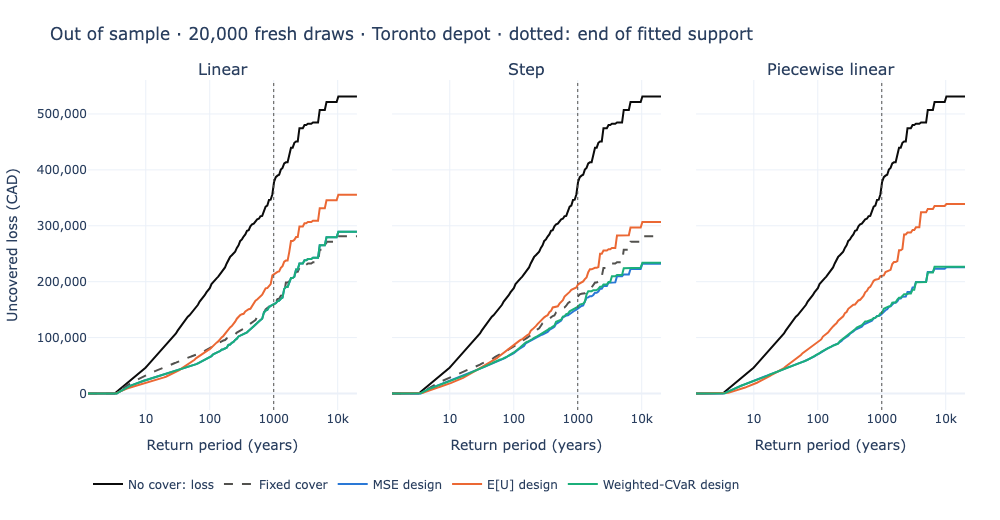

In [15]:
loss_model = LossModel(DAMAGE, value=ASSET["value_cad"], value_unit="CAD")
with warnings.catch_warnings(record=True):   # the same draws: their support counts are in the table above
    warnings.simplefilter("always")
    fresh = sample_curve(
        curve_row, metadata=metadata, n_draws=20_000,
        rng=np.random.default_rng(np.random.SeedSequence(7).spawn(1)[0]),
        loss_model=loss_model, basis_risk=BASIS_RISK, asset_id=ASSET["asset_id"],
    )
if set(rows.sample_hash) != {fresh.content_hash}:
    raise RuntimeError("The rebuilt sample differs from the plan's fresh draws.")
print(f"Fresh draws rebuilt: {fresh.content_hash}")

loss = fresh.loss[:, 0]
returns = np.geomspace(1.25, 20_000, 160)
shown = set()

def exceedance(values):
    return np.quantile(values, 1 - 1 / returns, method="inverted_cdf")

fig = make_subplots(rows=1, cols=3, shared_yaxes=True, horizontal_spacing=0.04,
                    subplot_titles=[name.capitalize() for name in FAMILIES])
for column, name in enumerate(FAMILIES, start=1):
    fig.add_trace(go.Scatter(x=returns, y=exceedance(loss), mode="lines", name="No cover: loss",
                             legendgroup="loss", showlegend=column == 1,
                             line=dict(color=LOSS_COLOUR, width=2)), row=1, col=column)
    for label, resolved in resolved_covers.items():
        if family(label) != name:
            continue
        uncovered = np.maximum(loss - resolved.payout_values(fresh.index[:, 0]), 0.0)
        fig.add_trace(go.Scatter(
            x=returns, y=exceedance(uncovered), mode="lines", name=legend_name(label),
            legendgroup=legend_name(label), showlegend=legend_name(label) not in shown,
            hovertemplate=f"{label}<br>return period %{{x:,.0f}} years<br>uncovered %{{y:,.0f}} CAD<extra></extra>",
            line=dict(color=colour(label), width=2, dash="dash" if objective_of(label) is None else "solid"),
        ), row=1, col=column)
        shown.add(legend_name(label))
    fig.add_vline(x=longest, line=dict(color=FIXED_COLOUR, dash="dot", width=1), row=1, col=column)
    fig.update_xaxes(title_text="Return period (years)", type="log", row=1, col=column)
fig.update_yaxes(title_text="Uncovered loss (CAD)", tickformat=",.0f", row=1, col=1)
fig.update_layout(height=520, legend=dict(orientation="h", yanchor="top", y=-0.18),
                  margin=dict(l=85, r=35, t=80, b=110),
                  title=f"Out of sample · 20,000 fresh draws · {ASSET['asset_id']} · dotted: end of fitted support")
fig.show()

## Read the results under their setup

Every number above holds for this setup and nothing more: one illustrative asset with a made-up value, CRC Open Rx1day under SSP5-8.5 at 2050 in one H3 cell, a hypothetical damage curve, impact noise with σ = 0.3, the pure premium with a budget of 60 % of the expected loss, designs on 20,000 simulated years and evaluation on 20,000 fresh ones. Statements about the objectives are statements about this setup, for example "on this illustrative asset, under pure pricing at this budget, the E[U] design covers … of the expected loss out of sample". A different site, damage curve, basis-risk model, budget, pricing or horizon can order the covers differently. The objectives weigh the years differently; which one suits a cover depends on what its owner needs, and none is better in general.

Things to try:

- **Another site or horizon**: change `ASSET`, `BOUNDS` and `HORIZON`. One asset at a time: each asset is designed and evaluated on its own sample.
- **Other goals or prices**: change the objectives, `Budget(ratio=...)` or `Budget(amount=...)`, add `Limit(...)`, or price with `CostOfCapitalLoad(rate, q)`.
- **Other basis risk**: change σ in `ImpactNoise`, and watch the basis-risk columns move.
- **Your own payouts or objectives**: `BinaryPayout`, a user `PayoutFunction`, or `UserObjective` for a goal of your own.
- **The functions behind the plan**: `sample_curve`, `design`, `evaluate` and `compare` work on numpy arrays and Arrow tables without I/O; see crc-sdk's [parametric covers page](https://github.com/RiskThinking/crc-sdk/blob/main/docs/parametric.md).

## Provenance and licence

The comparison file keeps the setup, the cover documents and hashes, the design records, the sources with their checksums, the licences, and the random-generator states. Asset values are never written. The comparison is derived data under its inputs' licences.

The CRC Open dataset is licensed under [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/) (`CC-BY-NC-4.0`), with attribution to *Riskthinking.AI bias-corrected climate distributions*: attribution is required, and commercial use needs a separate licence. Keep the release ID, the licence and the attribution with exported results.

In [16]:
evaluation = result.metadata.model_dump(mode="json")
origin = evaluation["sources"][0]["metadata"]["source"]
seeds = next(entry["details"] for entry in evaluation["setup"]["evaluations"]
             if "fresh_draws_seed" in entry["details"])
display(pd.DataFrame([dict(
    provider=origin["provider"], dataset=origin["dataset"], version=origin["version"],
    source_checksum=origin["checksum"], curve_file_sha256=evaluation["sources"][0]["details"]["file_sha256"],
    licence=origin["licence"], attribution=origin["attribution"],
    damage_curve=DAMAGE.definition_hash, plan_seed=seeds["plan_seed"], fresh_draws_seed=seeds["fresh_draws_seed"],
    comparison=str(result.output),
    comparison_sha256=hashlib.sha256(Path(result.output).read_bytes()).hexdigest(),
)]).T.rename(columns={0: "value"}))

,value
provider,RiskThinking
dataset,crc-open-fixture
version,ssp585-fixture-2026-10-08-v2
source_checksum,1732e42916b6c40be8995c35935066f6ec10e818d5b2604ed2eb0eefb9a2db68
curve_file_sha256,sha256:4cd0a8305b1eaf416480ce4e2d751bc15d89bb0d30190bc623047c4bc4d7f880
licence,CC-BY-NC-4.0
attribution,Riskthinking.AI bias-corrected climate distributions
damage_curve,sha256:c7873c876b3c83ac5aa94d04b094f1a3aa128d8c8907858dbcb456f59706a5b0
plan_seed,42
fresh_draws_seed,7
